In [51]:
from sklearn.datasets import load_breast_cancer

In [53]:
features, target = load_breast_cancer(as_frame = True, return_X_y = True)

In [55]:
features

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [57]:
target

0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int32

In [59]:
target = target.apply(lambda x : 1 if x==0 else 0)

In [61]:
from sklearn.model_selection import train_test_split

In [63]:
X_train,X_test,y_train,y_test = train_test_split(features,target,test_size=0.20, random_state = 42)

In [65]:
from sklearn.preprocessing import MinMaxScaler

In [67]:
scaler = MinMaxScaler()

scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)



LogisticRegression()

In [71]:
X_test_scaled.shape

(114, 30)

In [73]:
rw = X_test_scaled[1]

In [75]:
rw.shape

(30,)

In [77]:
rw = rw.reshape(1,-1)

In [79]:
log_reg.predict_proba(rw)

array([[0.0323986, 0.9676014]])

In [81]:
y_pred = log_reg.predict(X_test_scaled)

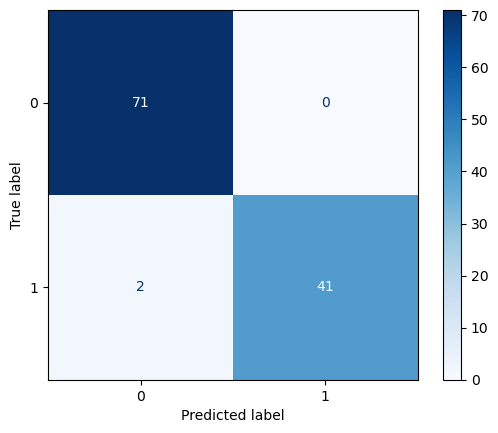

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [117]:
from sklearn.metrics import recall_score

In [119]:
recall_score(y_test, y_pred)

0.9069767441860465

In [84]:
log_reg.intercept_

array([-8.39455392])

In [87]:
log_reg.coef_

array([[ 1.76683167,  1.68189437,  1.71999936,  1.46715184,  0.60569659,
         0.34796767,  1.29843408,  2.01229654,  0.4775424 , -0.820699  ,
         1.13596413,  0.05251028,  0.85435219,  0.74879612,  0.04537074,
        -0.67290308, -0.28707315,  0.20816617, -0.296889  , -0.65024587,
         2.20615299,  2.27825938,  1.97392341,  1.56121154,  1.42171456,
         0.82535827,  1.28963211,  2.42084766,  1.37806655,  0.32037781]])

### Decision Tree

In [90]:
from sklearn.tree import DecisionTreeClassifier

In [94]:
dt = DecisionTreeClassifier(max_depth = 3)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3)

In [98]:
y_pred = dt.predict(X_test)

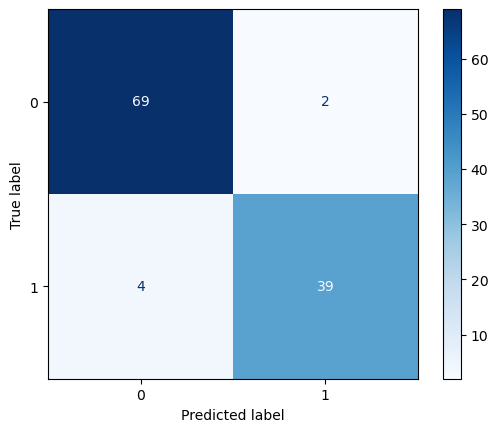

In [100]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [102]:
from sklearn.tree import plot_tree

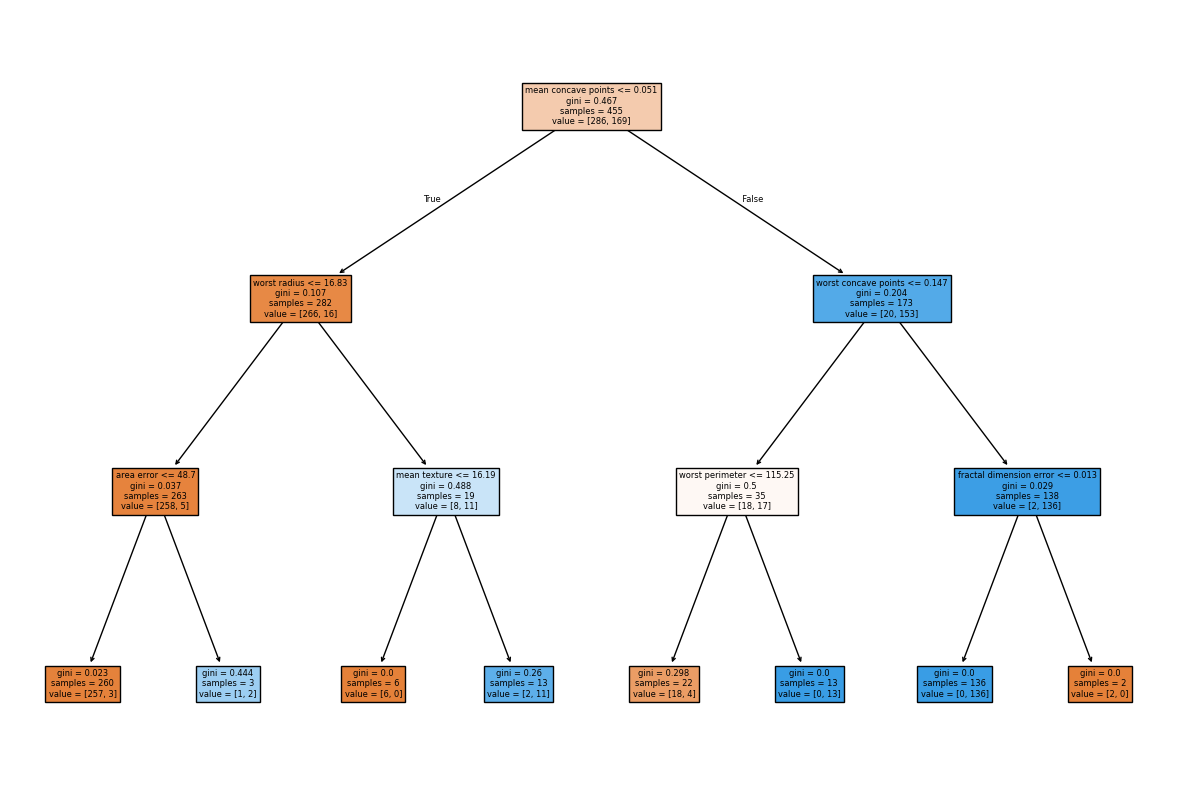

In [104]:
plt.figure(figsize=(15, 10))
plot_tree(dt, feature_names=X_train.columns, filled=True)
plt.show() 

### Random Forest

In [109]:
from sklearn.ensemble import RandomForestClassifier

In [111]:
rf = RandomForestClassifier()

In [113]:
rf.fit(X_train, y_train)

RandomForestClassifier()

In [121]:
y_pred = rf.predict(X_test)

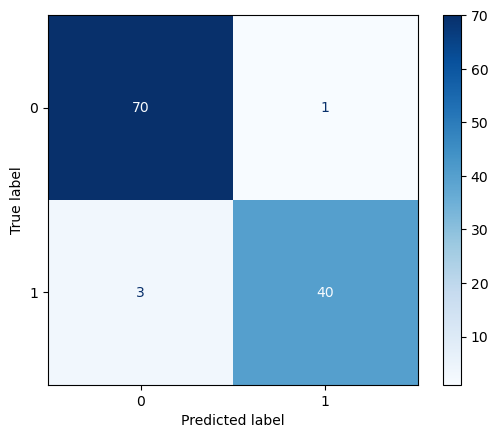

In [123]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [125]:
recall_score(y_test, y_pred)

0.9302325581395349